# 08 — Variant peptides proteome-wide: what is a genotype and what is not

Notebook 06 followed one variant. This notebook asks the general question: of all variant peptides the search reports, which ones reflect inherited variants of the donors?

Four filters are applied in turn, and the last step checks the result against population genetics:

1. **Class-specific FDR.** Variant peptides are a small class searched against a large space; the global 1% FDR does not hold within it. Decoy variant peptides are used to set a threshold for the class.
2. **Mass ambiguity.** A substitution whose mass shift equals a common chemical modification (or an isotope-peak error) of the reference peptide cannot be told apart from it.
3. **Carrier pattern.** A germline variant is present in some donors and absent in others, so its reporter ions must split the donors into two groups. Artefacts and amino-acid misincorporation are spread evenly. The threshold comes from an empirical null built from ordinary peptides.
4. **Population check.** For variants with a carrier pattern, the share of carriers among the 36 donors is compared with the value expected from East Asian allele frequencies (the cohort is Korean).

In [1]:
from pathlib import Path
import json, re, subprocess, sys
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"; EXT = ROOT / "data_external"
SEARCH = ROOT / "results_large" / "search_ALL_SETS"; VC = ROOT / "results_large" / "variant_class"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
VIOLET, GREY = "#6250d6", "#9a9a9a"

## 1. Class-specific FDR

`tools/extract_variant_class_psms.py` reads the unfiltered pep.xml files and keeps every rank-1 PSM that maps to a variant entry, target or decoy.
A peptide belongs to the variant class only if its sequence does not occur in any reference protein or contaminant (leucine and isoleucine treated as equal); for decoys the reversed sequence is tested.

In [2]:
if not (VC / "variant_class_psms_SET_4.done").exists():
    subprocess.run([sys.executable, str(ROOT / "tools" / "extract_variant_class_psms.py"), str(SEARCH), str(VC)], check=True, cwd=ROOT)

cache = VC / "variant_class_psms_all.tsv"
if cache.exists():
    v = pd.read_csv(cache, sep="\t")
else:
    def read_fasta(path):
        seqs, cur = [], []
        for line in open(path, encoding="utf-8"):
            if line.startswith(">"):
                if cur: seqs.append("".join(cur)); cur = []
            else:
                cur.append(line.strip())
        seqs.append("".join(cur)); return seqs
    REF = "|".join(read_fasta(EXT / "uniprot_human_reviewed.fasta") + read_fasta(EXT / "contaminants_HaoLab_universal.fasta")).replace("I", "L")
    d = pd.concat([pd.read_csv(f, sep="\t", header=None, names=["file", "spectrum", "peptide", "prob", "proteins"]) for f in sorted(VC.glob("variant_class_psms_SET_?.tsv"))])
    d = d[d["spectrum"] != "#psms_total"].copy(); d["prob"] = d["prob"].astype(float)
    d["decoy"] = d["proteins"].str.startswith("rev_")
    in_class = {p: (p.replace("I", "L") not in REF) and (p.replace("I", "L")[::-1] not in REF) for p in d["peptide"].unique()}
    v = d[d["peptide"].map(in_class)]
    v.to_csv(cache, sep="\t", index=False)

best = v.groupby(["peptide", "decoy"])["prob"].max().reset_index()
rows = []
for t in [0.5, 0.9, 0.99, 0.995, 0.999]:
    x = best[best["prob"] >= t]
    rows.append((t, int((~x["decoy"]).sum()), int(x["decoy"].sum()), round(100 * x["decoy"].sum() / max((~x["decoy"]).sum(), 1), 1)))
thr = None
for t in np.sort(best["prob"].unique())[::-1]:
    x = best[best["prob"] >= t]
    if x["decoy"].sum() / max((~x["decoy"]).sum(), 1) <= 0.01: thr = t
    else: break
x = best[best["prob"] >= thr]
rows.append((round(thr, 4), int((~x["decoy"]).sum()), int(x["decoy"].sum()), round(100 * x["decoy"].sum() / (~x["decoy"]).sum(), 1)))
fdr = pd.DataFrame(rows, columns=["min. PSM probability", "target variant peptides", "decoy variant peptides", "class FDR (%)"])
fdr.to_csv(RES / "variant_class_fdr.tsv", sep="\t", index=False)
keep = set(x.loc[~x["decoy"], "peptide"])
fdr

,min. PSM probability,target variant peptides,decoy variant peptides,class FDR (%)
0,0.5000,3873,1409,36.4
1,0.9000,2172,243,11.2
2,0.9900,1670,40,2.4
3,0.9950,1563,18,1.2
4,0.9990,1383,2,0.1
5,0.9967,1513,15,1.0


At the probability cut-off that corresponds to the global 1% FDR (about 0.6), roughly a third of the variant peptides are decoy-level matches. The class needs a much stricter threshold (last row), which is used from here on.

In [3]:
vt = pd.read_csv(RES / "variant_table.tsv", sep="\t").set_index("variant_entry")
pv = v[~v["decoy"] & v["peptide"].isin(keep)].drop_duplicates("peptide")[["peptide", "proteins"]].copy()
pv["entry"] = pv["proteins"].apply(lambda s: next(p.split("|")[1] for p in s.split(";") if re.match(r"sp\|[A-Z0-9]+_[A-Z]\d+[A-Z]\|", p)))
pv = pv.join(vt[["gene", "ref", "pos", "alt", "category", "dbsnp", "group"]], on="entry")

MASS = dict(G=57.02146, A=71.03711, S=87.03203, P=97.05276, V=99.06841, T=101.04768, C=103.00919, L=113.08406, I=113.08406, N=114.04293,
            D=115.02694, Q=128.05858, K=128.09496, E=129.04259, M=131.04049, H=137.05891, F=147.06841, R=156.10111, Y=163.06333, W=186.07931, U=150.95364)
MODS = {"deamidation / isotope error (+0.98)": 0.98402, "amidation / isotope error (-0.98)": -0.98402, "oxidation": 15.99491, "methylation": 14.01565,
        "dimethylation": 28.0313, "formylation": 27.99491, "acetylation": 42.01057, "carbamidomethylation": 57.02146, "carboxymethylation": 58.00548,
        "carbamylation": 43.00581, "ammonia loss": -17.02655, "water loss": -18.01056}
def ambiguity(r, a):
    if {r, a} == {"I", "L"}: return "Ile/Leu"
    d = MASS[a] - MASS[r]
    return next((name for name, m in MODS.items() if abs(d - m) < 0.006), "")
pv["mass_ambiguity"] = [ambiguity(r, a) for r, a in zip(pv["ref"], pv["alt"])]
print(len(pv), "variant peptides,", pv["entry"].nunique(), "variants,", pv["gene"].nunique(), "genes at 1% class FDR")
pv.drop_duplicates("entry")["mass_ambiguity"].replace("", "unambiguous").value_counts().rename("variants")

1513 variant peptides, 1293 variants, 820 genes at 1% class FDR


mass_ambiguity
unambiguous                            1013
methylation                              98
deamidation / isotope error (+0.98)      53
amidation / isotope error (-0.98)        43
carboxymethylation                       32
dimethylation                            31
oxidation                                23
Name: variants, dtype: int64

## 3. Carrier pattern

For every variant and TMT set, the reporter intensities of its peptides are summed per channel, divided by the pooled reference channel, and divided by the same ratio for all peptides of the gene:

`r = log2 [ (variant donor / variant pool) / (gene donor / gene pool) ]`

Donors are then split into a low and a high group at the position that maximises *gap / within-group SD* (difference of means at least one log2 unit).
The same statistic is computed for 6,000 ordinary peptides with similarly few PSMs; the 99th percentile of that null distribution, for the same number of TMT sets, is the threshold.

In [4]:
meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
variant_peps = set(pv["peptide"]); rng = np.random.default_rng(0)
var_rows, null_rows, gene_rows, chosen = [], [], [], None
for s in range(1, 5):
    d = pd.read_csv(SEARCH / f"SET_{s}" / "psm.tsv", sep="\t", low_memory=False,
                    usecols=lambda c: c in ("Peptide", "Gene", "Purity", "Is Unique") or c.startswith("Intensity "))
    d = d[d["Purity"] >= 0.5]
    ic = [c for c in d.columns if c.startswith("Intensity ")]
    def long(t, keys):
        t = t.groupby(keys)[ic].sum().reset_index(); t["set"] = s
        t = t.melt(id_vars=keys + ["set"], var_name="sample", value_name="I"); t["sample"] = t["sample"].str.replace("Intensity ", ""); return t
    var_rows.append(long(d[d["Peptide"].isin(variant_peps)], ["Peptide"]))
    plain = d[~d["Peptide"].isin(variant_peps) & d["Is Unique"]]
    if chosen is None:
        counts = plain["Peptide"].value_counts()
        chosen = set(rng.choice(np.sort(counts[counts <= 6].index.to_numpy()), 6000, replace=False))
    null_rows.append(long(plain[plain["Peptide"].isin(chosen)], ["Peptide", "Gene"]))
    gene_rows.append(long(d, ["Gene"]).rename(columns={"I": "I_gene"}))
    del d
G = pd.concat(gene_rows)

def ratios(t, key):
    t = t.merge(G, on=["Gene", "set", "sample"], how="left")
    t["pool"] = t["sample"].str.startswith("pool")
    pool = t[t["pool"]].set_index([key, "set"])[["I", "I_gene"]].rename(columns={"I": "I_pool", "I_gene": "I_gene_pool"})
    t = t[~t["pool"]].join(pool, on=[key, "set"])
    with np.errstate(divide="ignore", invalid="ignore"):
        t["r"] = np.log2((t["I"] / t["I_pool"]) / (t["I_gene"] / t["I_gene_pool"]))
    return t.replace([np.inf, -np.inf], np.nan).dropna(subset=["r"])

def split(y):
    y = np.sort(y); n = len(y); best = (0.0, 0, 0.0)
    for k in range(1, n):
        lo, hi = y[:k], y[k:]
        if hi.mean() - lo.mean() < 1: continue
        sd = max(np.sqrt((((lo - lo.mean()) ** 2).sum() + ((hi - hi.mean()) ** 2).sum()) / max(n - 2, 1)), 0.15)
        score = (hi[0] - lo[-1]) / sd
        if score > best[0]: best = (score, n - k, hi.mean() - lo.mean())
    return best

def table(D, key):
    out = [(e, x["set"].nunique(), len(x), *split(x["r"].to_numpy())) for e, x in D.groupby(key) if len(x) >= 9]
    return pd.DataFrame(out, columns=[key, "n_sets", "n_donors", "score", "n_carriers", "delta_log2"])

V = pd.concat(var_rows).merge(pv[["peptide", "entry", "gene"]], left_on="Peptide", right_on="peptide").rename(columns={"gene": "Gene"})
V = V.groupby(["entry", "Gene", "set", "sample"])["I"].sum().reset_index()
DV, DN = ratios(V, "entry"), ratios(pd.concat(null_rows), "Peptide")
TV, TN = table(DV, "entry"), table(DN, "Peptide")
null_q99 = TN.groupby("n_sets")["score"].quantile(0.99)
TV["threshold"] = TV["n_sets"].map(null_q99); TV["carrier_pattern"] = TV["score"] > TV["threshold"]
TV = TV.merge(pv.drop_duplicates("entry")[["entry", "gene", "ref", "pos", "alt", "dbsnp", "category", "group", "mass_ambiguity"]], on="entry")
print("null: 99th percentile of the score by number of TMT sets:", null_q99.round(2).to_dict())
print(len(TV), "variants assessed;", int(TV["carrier_pattern"].sum()), "with a carrier pattern; expected by chance:", round(0.01 * len(TV)))
pd.crosstab(TV["mass_ambiguity"].replace("", "unambiguous"), TV["carrier_pattern"].map({True: "pattern", False: "no pattern"}))

null: 99th percentile of the score by number of TMT sets: {1: 5.97, 2: 4.59, 3: 3.61, 4: 3.27}
1246 variants assessed; 66 with a carrier pattern; expected by chance: 12


carrier_pattern,no pattern,pattern
mass_ambiguity,,
amidation / isotope error (-0.98),38,3
carboxymethylation,30,1
deamidation / isotope error (+0.98),53,0
dimethylation,28,3
methylation,86,11
oxidation,22,0
unambiguous,923,48


In [5]:
# per-donor carrier calls for variants with a carrier pattern (used in notebook 09)
calls = []
for row in TV[TV["carrier_pattern"]].itertuples():
    x = DV[DV["entry"] == row.entry].sort_values("r", ascending=False).copy()
    x["carrier"] = np.arange(len(x)) < row.n_carriers
    calls.append(x[["entry", "Gene", "set", "sample", "r", "carrier"]])
calls = pd.concat(calls).rename(columns={"Gene": "gene", "set": "tmt_set", "r": "log2_variant_ratio"})
calls.to_csv(RES / "variant_carrier_calls.tsv", sep="\t", index=False)
print(calls["entry"].nunique(), "variants,", len(calls), "donor-level calls")

66 variants, 1422 donor-level calls


## 4. Population check

In [6]:
freq_file = RES / "ensembl_eas_frequencies.json"
ids = sorted(set(TV["dbsnp"]) - {"-"})
have = json.load(open(freq_file)) if freq_file.exists() else {}
if any(i not in have for i in ids):                      # about 15 minutes for 1,100 ids; cached afterwards
    (ROOT / "results_large" / "rsids.txt").write_text("\n".join(ids))
    subprocess.run([sys.executable, str(ROOT / "tools" / "fetch_population_frequencies.py"), str(ROOT / "results_large" / "rsids.txt")], check=True, cwd=ROOT)
    have = json.load(open(freq_file))

def eas_non_reference(rs):
    """Frequency of the non-reference allele(s) in East Asians (gnomAD genomes, else exomes, else 1000 Genomes)."""
    rec = have.get(rs)
    if not rec or not rec["freq"] or not rec["allele_string"]: return np.nan
    ref = rec["allele_string"].split("/")[0]
    for pop in ["gnomADg:eas", "gnomADe:eas", "1000GENOMES:phase_3:EAS"]:
        fr = [(a, f) for p, a, f in rec["freq"] if p == pop]
        if fr:
            r = [f for a, f in fr if a == ref]
            return 1 - r[0] if r else sum(f for _, f in fr)
    return np.nan

TV["eas_af"] = TV["dbsnp"].map(eas_non_reference)
TV["observed_carriers"] = np.where(TV["carrier_pattern"], TV["n_carriers"] / TV["n_donors"], np.nan)
TV["expected_carriers"] = 1 - (1 - TV["eas_af"]) ** 2
TV["af_class"] = pd.cut(TV["eas_af"], [-1, 0.0005, 0.01, 0.05, 0.95, 1.01], labels=["< 0.05%", "0.05-1%", "1-5%", "5-95%", "> 95%"])
TV.sort_values(["carrier_pattern", "score"], ascending=False).to_csv(RES / "variant_carrier_patterns.tsv", sep="\t", index=False)
u = TV[(TV["mass_ambiguity"] == "") & TV["eas_af"].notna()]
by_af = u.groupby("af_class", observed=True)["carrier_pattern"].agg(variants="size", with_pattern="sum")
by_af["with_pattern_%"] = (100 * by_af["with_pattern"] / by_af["variants"]).round(1)
by_af

,variants,with_pattern,with_pattern_%
af_class,,,
< 0.05%,201,2,1.0
0.05-1%,21,2,9.5
1-5%,30,9,30.0
5-95%,386,30,7.8
> 95%,64,0,0.0


Variants that are essentially absent from East Asian populations (< 0.05%) and variants that are fixed (> 95%) are detected as peptides but almost never show a carrier pattern, as expected: the former are not inherited variants of these donors, the latter are carried by everyone.
Detection of a variant peptide alone, even at 1% class FDR, is therefore not evidence of a genotype.
Among common variants (5-95%) only a minority exceed the strict threshold; this reflects limited sensitivity, discussed below.

In [7]:
p = u[u["carrier_pattern"] & (u["n_sets"] == 4)].copy()
rho, pval = stats.spearmanr(p["observed_carriers"], p["expected_carriers"])
print(f"{len(p)} unambiguous variants with a carrier pattern, quantified in all four TMT sets (36 donors)")
print(f"observed vs expected share of carriers: Spearman rho = {rho:.2f}, p = {pval:.4f}; median absolute difference = {(p['observed_carriers'] - p['expected_carriers']).abs().median():.2f}")
p[["gene", "ref", "pos", "alt", "dbsnp", "eas_af", "expected_carriers", "observed_carriers", "score", "category"]].sort_values("expected_carriers").round(2)

16 unambiguous variants with a carrier pattern, quantified in all four TMT sets (36 donors)
observed vs expected share of carriers: Spearman rho = 0.94, p = 0.0000; median absolute difference = 0.04


,gene,ref,pos,alt,dbsnp,eas_af,expected_carriers,observed_carriers,score,category
420,PRDX3,T,234,I,rs35697338,0.02,0.04,0.03,3.79,LB/B
1191,UQCR10,I,47,V,rs76013375,0.08,0.15,0.19,4.78,LB/B
486,ALDH7A1,K,439,Q,rs12514417,0.15,0.28,0.25,4.47,LB/B
190,TFRC,G,142,S,rs3817672,0.16,0.29,0.42,3.91,LB/B
1244,NDUFB9,P,146,S,rs10195,0.17,0.31,0.33,4.08,LB/B
268,GSTP1,I,105,V,rs1695,0.18,0.33,0.47,4.02,LB/B
1155,NANS,E,68,D,rs1058446,0.19,0.35,0.56,3.44,LB/B
941,VPS13C,I,1132,V,rs3784635,0.21,0.37,0.47,3.40,LB/B
215,ALDH2,E,504,K,rs671,0.22,0.40,0.28,5.03,LP/P
413,PSMB4,I,234,T,rs4603,0.34,0.56,0.67,4.67,LB/B


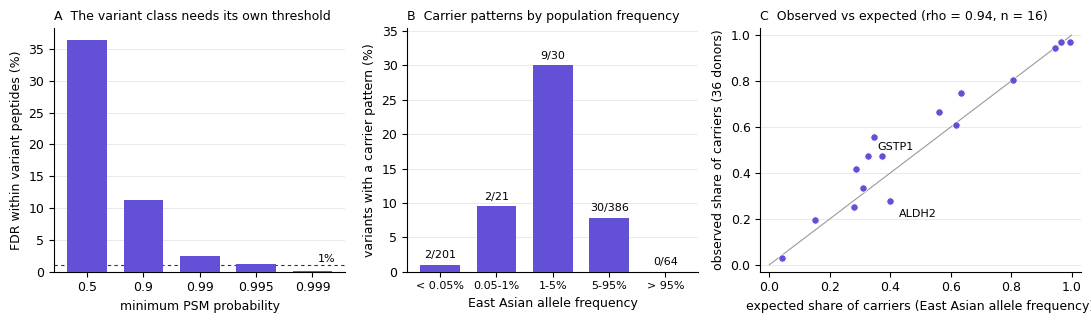

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 1, 1.1]})
f = pd.read_csv(RES / "variant_class_fdr.tsv", sep="\t").iloc[:-1]
ax[0].bar(range(len(f)), f["class FDR (%)"], color=VIOLET, width=0.7, zorder=3)
ax[0].set_xticks(range(len(f))); ax[0].set_xticklabels(f["min. PSM probability"].astype(str))
ax[0].axhline(1, color="#333333", lw=0.8, ls=(0, (3, 3))); ax[0].text(len(f) - 0.6, 1.6, "1%", ha="right", fontsize=8)
ax[0].set_xlabel("minimum PSM probability"); ax[0].set_ylabel("FDR within variant peptides (%)")
ax[0].set_title("A  The variant class needs its own threshold", fontsize=9, loc="left")
ax[1].bar(range(len(by_af)), by_af["with_pattern_%"], color=VIOLET, width=0.7, zorder=3)
for i, (n, k) in enumerate(zip(by_af["variants"], by_af["with_pattern"])):
    ax[1].text(i, by_af["with_pattern_%"].iloc[i] + 1, f"{k}/{n}", ha="center", fontsize=8)
ax[1].set_xticks(range(len(by_af))); ax[1].set_xticklabels(by_af.index, fontsize=8)
ax[1].set_xlabel("East Asian allele frequency"); ax[1].set_ylabel("variants with a carrier pattern (%)")
ax[1].set_ylim(0, by_af["with_pattern_%"].max() * 1.18)
ax[1].set_title("B  Carrier patterns by population frequency", fontsize=9, loc="left")
ax[2].plot([0, 1], [0, 1], color=GREY, lw=0.8, zorder=1)
ax[2].scatter(p["expected_carriers"], p["observed_carriers"], s=28, color=VIOLET, edgecolor="white", linewidth=0.6, zorder=3)
for gname, dx, dy in [("ALDH2", 0.03, -0.07), ("GSTP1", 0.03, 0.03)]:
    q = p[p["gene"] == gname]
    if len(q): ax[2].annotate(gname, (q["expected_carriers"].iloc[0], q["observed_carriers"].iloc[0]), xytext=(q["expected_carriers"].iloc[0] + dx, q["observed_carriers"].iloc[0] + dy), fontsize=8)
ax[2].set_xlim(-0.03, 1.03); ax[2].set_ylim(-0.03, 1.03)
ax[2].set_xlabel("expected share of carriers (East Asian allele frequency)"); ax[2].set_ylabel("observed share of carriers (36 donors)")
ax[2].set_title(f"C  Observed vs expected (rho = {rho:.2f}, n = {len(p)})", fontsize=9, loc="left")
for a in ax:
    a.grid(axis="y", color="#e6e6e6", lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_variant_peptides_proteome_wide.png", dpi=300); plt.show()

## Cytochromes P450, their partners and the pathway genes

In [9]:
panel = TV[TV["group"] != "all"].sort_values(["carrier_pattern", "score"], ascending=False)
panel[["gene", "ref", "pos", "alt", "dbsnp", "category", "mass_ambiguity", "n_sets", "score", "threshold", "carrier_pattern", "n_carriers", "n_donors", "eas_af"]].round(2)

,gene,ref,pos,alt,dbsnp,category,mass_ambiguity,n_sets,score,threshold,carrier_pattern,n_carriers,n_donors,eas_af
215,ALDH2,E,504,K,rs671,LP/P,,4,5.03,3.27,True,10,36,0.22
268,GSTP1,I,105,V,rs1695,LB/B,,4,4.02,3.27,True,17,36,0.18
236,EPHX1,R,43,T,rs3738046,LB/B,,1,4.93,5.97,False,1,9,0.04
343,GFAP,Y,257,C,rs267607505,LP/P,,1,3.87,5.97,False,8,9,NaN
180,APOE,R,176,C,rs7412,LP/P,,2,3.56,4.59,False,2,18,0.08
396,FDXR,C,353,Y,-,US,,2,2.76,4.59,False,5,18,NaN
390,COMT,V,158,M,rs4680,LB/B,,4,2.72,3.27,False,14,36,0.27
361,POR,A,500,V,rs1057868,LB/B,dimethylation,4,2.65,3.27,False,25,36,0.38
340,GFAP,P,47,L,rs57474185,LB/B,,2,2.57,4.59,False,17,18,0.00
336,GFAP,L,101,P,rs267607516,LP/P,,4,2.13,3.27,False,35,36,NaN


## Conclusions

- Variant peptides must be controlled as a class: the threshold that gives 1% FDR globally gives a far higher error rate among them.
- After class-specific FDR, a large share of the remaining variant peptides still cannot be germline variants of these donors (frequency below 0.05% in East Asians, no carrier pattern). They are best explained by modifications, misincorporation or residual false matches.
- The carrier pattern, with a threshold taken from ordinary peptides, separates inherited variants from these. For variants with a pattern in all four TMT sets, the share of carriers agrees with East Asian allele frequencies.
- The strict threshold costs sensitivity: common variants such as *COMT* Val158Met or *POR* Ala503Val show the expected number of carriers but fall just below it. MS2-level TMT compresses the contrast between carriers and non-carriers.
- In the cytochrome panel, peptides of several variants are detected (CYP20A1, POR, FDXR, EPHX1, GSTP1, COMT, APOE, ALDH2); a carrier pattern above the threshold is reached for ALDH2 and GSTP1. Liver-type pharmacogenes (CYP2D6, CYP2C19, CYP2C9, CYP3A4/5) yield no variant peptide in bulk cortex.

With the genome of each donor available, as planned in MOSAIC-S, the carrier pattern is no longer inferred: the search database is built from the donor's own variants and the proteome is used to measure their consequences.